<img src="./assets/ga-logo.png" style="float: left; margin: 20px; height: 55px">

# Lab: Simple Linear Regression with Sacramento Real Estate Data

---

In this lab you will hone your exploratory data analysis (EDA) skills and practice constructing linear regressions on a data set of Sacramento real estate sales.  The data set contains information on qualities of the property, location of the property, and time of sale.

# Author: "REPLACE THIS WITH YOUR NAME"

### 1. Read in the Sacramento housing data set.

The file is stored in the `data` subfolder.

In [1]:
import pandas as pd
import numpy as np

### 2. Conduct exploratory data analysis on this data set. 

If you discover any issues with the data, fix them to the best of your ability. Report any notable findings.

_**Note:** Zip codes often have leading zeros — e.g., 02215 = Boston, MA — which will often get knocked off automatically by many software programs like Python or Excel._

In [2]:
df = pd.read_csv("../01 - Regression-Sacramento/data/sacramento_real_estate_transactions.csv")
df.head(10)

,street,city,zip,state,beds,baths,sq__ft,type,sale_date,price,latitude,longitude
0,3526 HIGH ST,SACRAMENTO,95838,CA,2,1,836,Residential,Wed May 21 00:00:00 EDT 2008,59222,38.631913,-121.434879
1,51 OMAHA CT,SACRAMENTO,95823,CA,3,1,1167,Residential,Wed May 21 00:00:00 EDT 2008,68212,38.478902,-121.431028
2,2796 BRANCH ST,SACRAMENTO,95815,CA,2,1,796,Residential,Wed May 21 00:00:00 EDT 2008,68880,38.618305,-121.443839
3,2805 JANETTE WAY,SACRAMENTO,95815,CA,2,1,852,Residential,Wed May 21 00:00:00 EDT 2008,69307,38.616835,-121.439146
4,6001 MCMAHON DR,SACRAMENTO,95824,CA,2,1,797,Residential,Wed May 21 00:00:00 EDT 2008,81900,38.519470,-121.435768
5,5828 PEPPERMILL CT,SACRAMENTO,95841,CA,3,1,1122,Condo,Wed May 21 00:00:00 EDT 2008,89921,38.662595,-121.327813
6,6048 OGDEN NASH WAY,SACRAMENTO,95842,CA,3,2,1104,Residential,Wed May 21 00:00:00 EDT 2008,90895,38.681659,-121.351705
7,2561 19TH AVE,SACRAMENTO,95820,CA,3,1,1177,Residential,Wed May 21 00:00:00 EDT 2008,91002,38.535092,-121.481367
8,11150 TRINITY RIVER DR Unit 114,RANCHO CORDOVA,95670,CA,2,2,941,Condo,Wed May 21 00:00:00 EDT 2008,94905,38.621188,-121.270555
9,7325 10TH ST,RIO LINDA,95673,CA,3,2,1146,Residential,Wed May 21 00:00:00 EDT 2008,98937,38.700909,-121.442979


In [3]:
df.shape

(985, 12)

In [4]:
df.describe(include='all')

,street,city,zip,state,beds,baths,sq__ft,type,sale_date,price,latitude,longitude
count,985,985,985.000000,985,985.000000,985.000000,985.000000,985,985,985.000000,985.000000,985.000000
unique,981,39,NaN,2,NaN,NaN,NaN,4,5,NaN,NaN,NaN
top,4734 14TH AVE,SACRAMENTO,NaN,CA,NaN,NaN,NaN,Residential,Mon May 19 00:00:00 EDT 2008,NaN,NaN,NaN
freq,2,439,NaN,984,NaN,NaN,NaN,917,268,NaN,NaN,NaN
mean,NaN,NaN,95750.697462,NaN,2.911675,1.776650,1312.918782,NaN,NaN,233715.951269,38.445121,-121.193371
std,NaN,NaN,85.176072,NaN,1.307932,0.895371,856.123224,NaN,NaN,139088.818896,5.103637,5.100670
min,NaN,NaN,95603.000000,NaN,0.000000,0.000000,-984.000000,NaN,NaN,-210944.000000,-121.503471,-121.551704
25%,NaN,NaN,95660.000000,NaN,2.000000,1.000000,950.000000,NaN,NaN,145000.000000,38.482704,-121.446119
50%,NaN,NaN,95762.000000,NaN,3.000000,2.000000,1304.000000,NaN,NaN,213750.000000,38.625932,-121.375799
75%,NaN,NaN,95828.000000,NaN,4.000000,2.000000,1718.000000,NaN,NaN,300000.000000,38.695589,-121.294893


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 985 entries, 0 to 984
Data columns (total 12 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   street     985 non-null    str    
 1   city       985 non-null    str    
 2   zip        985 non-null    int64  
 3   state      985 non-null    str    
 4   beds       985 non-null    int64  
 5   baths      985 non-null    int64  
 6   sq__ft     985 non-null    int64  
 7   type       985 non-null    str    
 8   sale_date  985 non-null    str    
 9   price      985 non-null    int64  
 10  latitude   985 non-null    float64
 11  longitude  985 non-null    float64
dtypes: float64(2), int64(5), str(5)
memory usage: 156.9 KB


In [6]:
df['city'].value_counts()

city
SACRAMENTO         439
ELK GROVE          114
LINCOLN             72
ROSEVILLE           48
CITRUS HEIGHTS      35
ANTELOPE            33
RANCHO CORDOVA      28
EL DORADO HILLS     23
NORTH HIGHLANDS     21
GALT                21
CARMICHAEL          20
FOLSOM              17
ROCKLIN             17
RIO LINDA           13
ORANGEVALE          11
PLACERVILLE         10
FAIR OAKS            9
CAMERON PARK         9
WILTON               5
AUBURN               5
ELVERTA              4
GOLD RIVER           4
POLLOCK PINES        3
RANCHO MURIETA       3
GRANITE BAY          3
WEST SACRAMENTO      3
LOOMIS               2
EL DORADO            2
MATHER               1
GREENWOOD            1
MEADOW VISTA         1
PENRYN               1
FORESTHILL           1
DIAMOND SPRINGS      1
SHINGLE SPRINGS      1
COOL                 1
WALNUT GROVE         1
GARDEN VALLEY        1
SLOUGHHOUSE          1
Name: count, dtype: int64

In [7]:
df['zip'].sort_values(ascending=True)

484    95603
852    95603
833    95603
468    95603
325    95603
       ...  
172    95864
156    95864
851    95864
793    95864
423    95864
Name: zip, Length: 985, dtype: int64

In [8]:
df[df['latitude']<-100]

,street,city,zip,state,beds,baths,sq__ft,type,sale_date,price,latitude,longitude
703,1900 DANBROOK DR,SACRAMENTO,95835,AC,1,1,-984,Condo,Fri May 16 00:00:00 EDT 2008,-210944,-121.503471,38.668433


In [9]:
df[df['price']<0]

,street,city,zip,state,beds,baths,sq__ft,type,sale_date,price,latitude,longitude
703,1900 DANBROOK DR,SACRAMENTO,95835,AC,1,1,-984,Condo,Fri May 16 00:00:00 EDT 2008,-210944,-121.503471,38.668433


In [10]:
df[df['sq__ft']<0]

,street,city,zip,state,beds,baths,sq__ft,type,sale_date,price,latitude,longitude
703,1900 DANBROOK DR,SACRAMENTO,95835,AC,1,1,-984,Condo,Fri May 16 00:00:00 EDT 2008,-210944,-121.503471,38.668433


In [11]:
# Only one row has a suspicious valus. It seems like lat and lon are replaced, sq_ft and price are negative instead of positive
# Because 1 rejected row will now affect dataset, I decide to reject it instead of changing negative to positive sq_ft and price and replace lat with lon.

df.drop(axis=0, index=703, inplace=True) 

In [12]:
df.reset_index(inplace=True)
df.drop(columns='index', inplace=True)

In [13]:
df.describe(include='all')

,street,city,zip,state,beds,baths,sq__ft,type,sale_date,price,latitude,longitude
count,984,984,984.000000,984,984.000000,984.000000,984.000000,984,984,984.000000,984.000000,984.000000
unique,980,39,NaN,1,NaN,NaN,NaN,4,5,NaN,NaN,NaN
top,4734 14TH AVE,SACRAMENTO,NaN,CA,NaN,NaN,NaN,Residential,Mon May 19 00:00:00 EDT 2008,NaN,NaN,NaN
freq,2,438,NaN,984,NaN,NaN,NaN,917,268,NaN,NaN,NaN
mean,NaN,NaN,95750.611789,NaN,2.913618,1.777439,1315.253049,NaN,NaN,234167.841463,38.607670,-121.355832
std,NaN,NaN,85.176913,NaN,1.307175,0.895484,853.416702,NaN,NaN,138434.220875,0.145494,0.138268
min,NaN,NaN,95603.000000,NaN,0.000000,0.000000,0.000000,NaN,NaN,1551.000000,38.241514,-121.551704
25%,NaN,NaN,95660.000000,NaN,2.000000,1.000000,951.500000,NaN,NaN,145000.000000,38.482714,-121.446121
50%,NaN,NaN,95762.000000,NaN,3.000000,2.000000,1304.000000,NaN,NaN,214375.000000,38.626257,-121.376010
75%,NaN,NaN,95828.000000,NaN,4.000000,2.000000,1718.500000,NaN,NaN,300000.000000,38.695611,-121.295557


In [14]:
df[df['sq__ft']==0]

,street,city,zip,state,beds,baths,sq__ft,type,sale_date,price,latitude,longitude
73,17 SERASPI CT,SACRAMENTO,95834,CA,0,0,0,Residential,Wed May 21 00:00:00 EDT 2008,206000,38.631481,-121.501880
89,2866 KARITSA AVE,SACRAMENTO,95833,CA,0,0,0,Residential,Wed May 21 00:00:00 EDT 2008,244500,38.626671,-121.525970
100,12209 CONSERVANCY WAY,RANCHO CORDOVA,95742,CA,0,0,0,Residential,Wed May 21 00:00:00 EDT 2008,263500,38.553867,-121.219141
121,5337 DUSTY ROSE WAY,RANCHO CORDOVA,95742,CA,0,0,0,Residential,Wed May 21 00:00:00 EDT 2008,320000,38.528575,-121.228600
126,2115 SMOKESTACK WAY,SACRAMENTO,95833,CA,0,0,0,Residential,Wed May 21 00:00:00 EDT 2008,339500,38.602416,-121.542965
...,...,...,...,...,...,...,...,...,...,...,...,...
933,1550 TOPANGA LN Unit 207,LINCOLN,95648,CA,0,0,0,Condo,Thu May 15 00:00:00 EDT 2008,188000,38.884170,-121.270222
946,1525 PENNSYLVANIA AVE,WEST SACRAMENTO,95691,CA,0,0,0,Residential,Thu May 15 00:00:00 EDT 2008,200100,38.569943,-121.527539
965,9197 CORTINA CIR,ROSEVILLE,95678,CA,3,2,0,Condo,Thu May 15 00:00:00 EDT 2008,220000,38.793152,-121.290025
969,3557 SODA WAY,SACRAMENTO,95834,CA,0,0,0,Residential,Thu May 15 00:00:00 EDT 2008,224000,38.631026,-121.501879


In [15]:
#There are 171 rows with wrong sq_ft values = 0 
# AS I plan to use sq_ft as main feature, I will drop every row with sq_ft = 0

dataframe = df[df['sq__ft']!=0]

In [16]:
dataframe.describe(include='all')

,street,city,zip,state,beds,baths,sq__ft,type,sale_date,price,latitude,longitude
count,813,813,813.000000,813,813.000000,813.000000,813.000000,813,813,813.000000,813.000000,813.000000
unique,810,36,NaN,1,NaN,NaN,NaN,3,5,NaN,NaN,NaN
top,4734 14TH AVE,SACRAMENTO,NaN,CA,NaN,NaN,NaN,Residential,Fri May 16 00:00:00 EDT 2008,NaN,NaN,NaN
freq,2,423,NaN,813,NaN,NaN,NaN,759,215,NaN,NaN,NaN
mean,NaN,NaN,95761.400984,NaN,3.247232,1.961870,1591.892989,NaN,NaN,229471.130381,38.576931,-121.378533
std,NaN,NaN,85.357516,NaN,0.849012,0.669367,663.908347,NaN,NaN,119897.576889,0.126352,0.119730
min,NaN,NaN,95603.000000,NaN,1.000000,1.000000,484.000000,NaN,NaN,2000.000000,38.241514,-121.550527
25%,NaN,NaN,95670.000000,NaN,3.000000,2.000000,1144.000000,NaN,NaN,148750.000000,38.473814,-121.451444
50%,NaN,NaN,95820.000000,NaN,3.000000,2.000000,1419.000000,NaN,NaN,207973.000000,38.591618,-121.404999
75%,NaN,NaN,95828.000000,NaN,4.000000,2.000000,1851.000000,NaN,NaN,285000.000000,38.674864,-121.325730


When you've finished cleaning or have made a good deal of progress cleaning, it's always a good idea to save your work. Use the pandas `to_csv` method to export your cleaned dataset.

```python
# example -- your dataframe name may be different
dataframe.to_csv('./datasets/sacramento_cleaned_dataframe.csv', index=False)

```

In [17]:
dataframe.to_csv('./data/sacramento_cleaned_dataframe.csv', index=False)

In [18]:
df = pd.read_csv('./data/sacramento_cleaned_dataframe.csv', index_col=False)
df.head()

,street,city,zip,state,beds,baths,sq__ft,type,sale_date,price,latitude,longitude
0,3526 HIGH ST,SACRAMENTO,95838,CA,2,1,836,Residential,Wed May 21 00:00:00 EDT 2008,59222,38.631913,-121.434879
1,51 OMAHA CT,SACRAMENTO,95823,CA,3,1,1167,Residential,Wed May 21 00:00:00 EDT 2008,68212,38.478902,-121.431028
2,2796 BRANCH ST,SACRAMENTO,95815,CA,2,1,796,Residential,Wed May 21 00:00:00 EDT 2008,68880,38.618305,-121.443839
3,2805 JANETTE WAY,SACRAMENTO,95815,CA,2,1,852,Residential,Wed May 21 00:00:00 EDT 2008,69307,38.616835,-121.439146
4,6001 MCMAHON DR,SACRAMENTO,95824,CA,2,1,797,Residential,Wed May 21 00:00:00 EDT 2008,81900,38.519470,-121.435768


# Single Linear Regression Model (SLR)

### 3. Our goal will be to predict price. List variables that you think qualify as predictors of price in an SLR model.

For each of the variables you believe should be considered, generate a plot showing the relationship between the independent and dependent variables.

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

In [20]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 813 entries, 0 to 812
Data columns (total 12 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   street     813 non-null    str    
 1   city       813 non-null    str    
 2   zip        813 non-null    int64  
 3   state      813 non-null    str    
 4   beds       813 non-null    int64  
 5   baths      813 non-null    int64  
 6   sq__ft     813 non-null    int64  
 7   type       813 non-null    str    
 8   sale_date  813 non-null    str    
 9   price      813 non-null    int64  
 10  latitude   813 non-null    float64
 11  longitude  813 non-null    float64
dtypes: float64(2), int64(5), str(5)
memory usage: 129.5 KB


<Axes: >

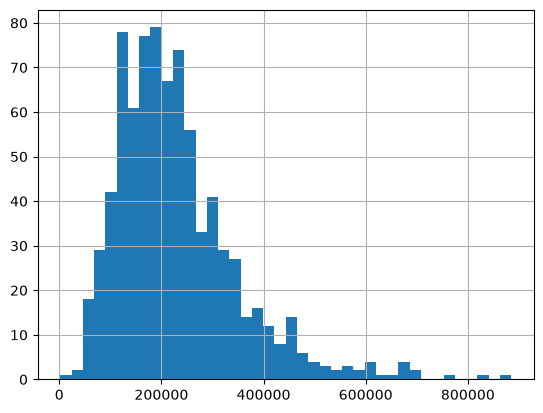

In [21]:
df['price'].hist(bins=40)

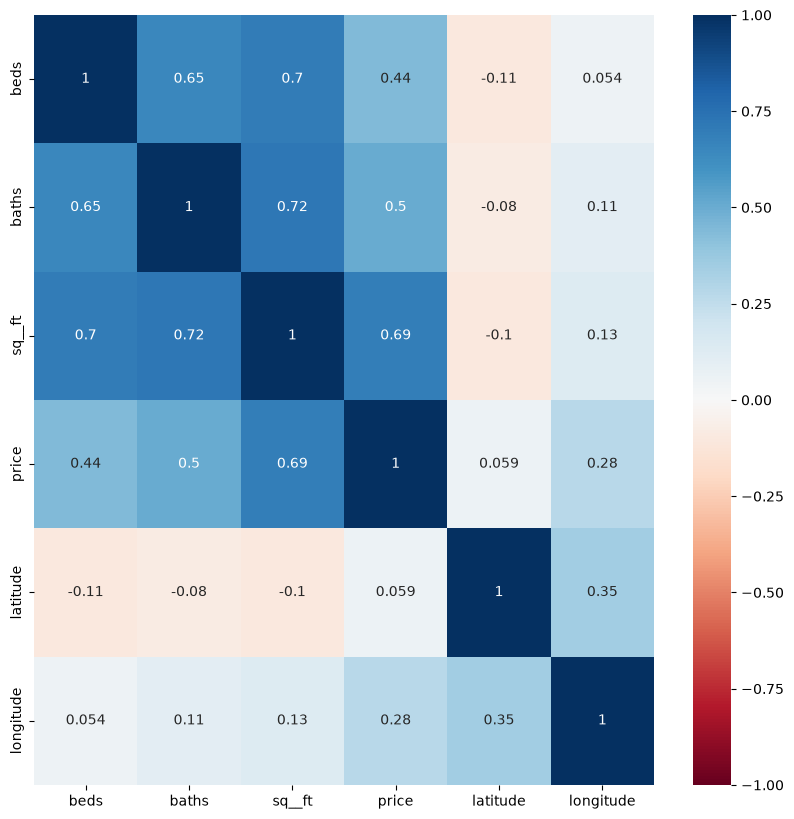

In [22]:
plt.figure(figsize=(10, 10))
sns.heatmap(
    df[['beds','baths', 'sq__ft', 'price', 'latitude', 'longitude']].corr(),
    cmap='RdBu',
    annot=True,
    vmin=-1,
    vmax=1
);

### 4. Which variable would be the best predictor of Y in an SLR model? Why?

In [23]:
# From the real estate POV, the best predictoe would be 'price' column.

y = df['price']
X = df[['sq__ft']]

### 5. Using `scikit-learn` create a SLR and return the intercept and slope coefficients that minimize SSE. 

#### SSE (Sum of Squared Errors)

SSE is just the total of all the squared prediction mistakes.

1. For each data point, figure out how far off your prediction was (actual minus predicted).
2. Square that number (to make negatives positive and punish big errors more).
3. Add them all up.

**Why it matters:** You were asked to find the slope and intercept that **minimize SSE**. That's literally what linear regression does — it searches for the line that makes this total as small as possible.

**Related terms:**
- **MSE** = SSE ÷ n (average of the squared errors)
- **RMSE** = √MSE (puts it back in original units)

So: **SSE → MSE → RMSE** is just the same number, adjusted differently for interpretation purposes.


-----

You may need to load in the scikit-learn API:

```python
from sklearn.linear_model import LinearRegression

model = LinearRegression()
```



In [24]:
from sklearn.linear_model import LinearRegression

In [25]:
model = LinearRegression()

In [26]:
## after plotting residual I will drop here row with sq__ft >58000 becasue price is 2000

df[df['sq__ft']>5800]

,street,city,zip,state,beds,baths,sq__ft,type,sale_date,price,latitude,longitude
703,14151 INDIO DR,SLOUGHHOUSE,95683,CA,3,4,5822,Residential,Fri May 16 00:00:00 EDT 2008,2000,38.490447,-121.129337


In [27]:
dfN = df[df['sq__ft']<5800]

In [28]:
yN = dfN['price']
XN = dfN[['sq__ft']]

In [29]:
model.fit(X, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[125.31]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['sq__ft']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2.998e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [30]:
model.fit(XN, yN)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[134.75]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['sq__ft']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,1.594e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [31]:
y_pred = model.predict(X)

In [32]:
y_predN = model.predict(XN)
y_predN.shape

(812,)

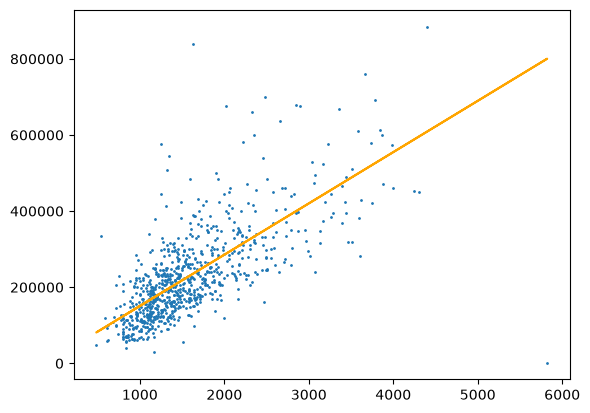

In [33]:
plt.scatter(df["sq__ft"], df["price"], s=1)
plt.plot(df["sq__ft"], y_pred, color='orange');

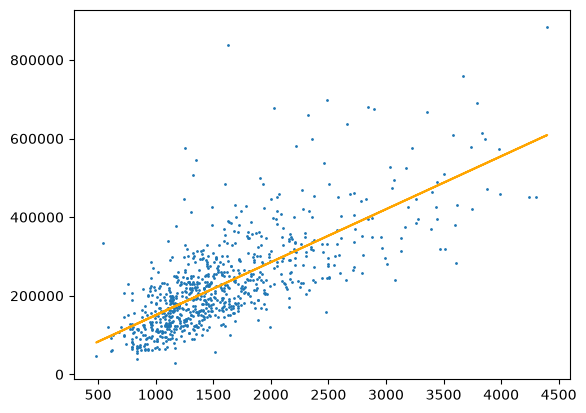

In [34]:
plt.scatter(dfN["sq__ft"], dfN["price"], s=1)
plt.plot(dfN["sq__ft"], y_predN, color='orange');

In [35]:
from sklearn.metrics import root_mean_squared_error, mean_squared_error

RMSE = root_mean_squared_error(y_pred, y)
MSE = mean_squared_error(y_pred, y)
SSE = ((y_pred -y)**2).sum()

print("RMSE = %.2f \nMSE = %.2f \nSSE = %.2f" %(RMSE, MSE, SSE))

RMSE = 86513.98 
MSE = 7484668620.18 
SSE = 6085035588208.04


In [36]:
from sklearn.metrics import root_mean_squared_error, mean_squared_error

RMSEN = root_mean_squared_error(y_predN, yN)
MSEN = mean_squared_error(y_predN, yN)
SSEN = ((y_predN -yN)**2).sum()

print("RMSE = %.2f \nMSE = %.2f \nSSE = %.2f" %(RMSEN, MSEN, SSEN))

RMSE = 81906.84 
MSE = 6708730030.06 
SSE = 5447488784410.81


In [37]:
RMSEN/RMSE

0.946746851036143

### 5 [bonus]. Write a function that will take in two lists, `x` and `y`, and return the intercept and slope coefficients that minimize SSE. 

`y` is the target variable, and `x` is the predictor variable.

**Don't use `scikit-learn` for this**. Instead, use `numpy` and `scipy`.

The slope and intercept of simple linear regression can be calculated by using certain summary statistics. In particular, we'll need to know:

- $\bar{x}$, the mean of `x`
- $\bar{y}$, the mean of `y`
- $s_{x}$, the standard deviation of `x`
- $s_{y}$, the standard deviation of `y`
- $r_{xy}$, the correlation of `x` and `y`

Given these summary statistics, the **coefficient on `X`** (or the slope) can be given by $\beta_{1} = r_{xy} * \frac{s_{y}}{s_{x}}$. The **intercept of the model** can be given by $\beta_{0} = \bar{y} - \beta_{1}\bar{x}$.

Your function should take in `x` and `y`, then use the above summary statistics to calculate the slope and intercept.

- **Test your function on price and the variable you determined was the best predictor in Problem 4.**
- **Report the slope and intercept.**

In [38]:
def linear_reg(X, y):

    """Takes X, y, returns slope, intercept"""

    X = np.array(X).ravel()
    y = np.array(y)

    x_mean = X.mean()
    y_mean = y.mean()

    x_std = np.std(X)
    y_std = np.std(y)

    r2 = np.corrcoef(X, y )[1][0]

    slope = r2*(y_std/x_std)
    intercept = y_mean - slope*x_mean

    return slope, intercept

In [39]:
slope, intercept = linear_reg(X, y)
print("intercept = %.2f\nslope = %.2f" %(intercept, slope))

intercept = 29984.36
slope = 125.31


In [40]:
model.intercept_

np.float64(15943.749961489259)

### 6. Interpret the intercept and the slope.

In your own words, write here what is the meaning of each one of those values
and how can they be helpful for you when predicting prices or interpreting the
predictions of your model.

In [41]:
# Intercept means the value of y when X = 0. In this case it is price for 0 sq__ft
# Slope give us how much change y with changing X in positive direction. It can be positive, for positive correlated values for X and y, or negative for the negative correlated values for X and y.

### 7. Give an example of how this model could be used for prediction and how it could be used for inference. 

**Be sure to make it clear which example is associated with prediction and which is associated with inference.**

In [42]:
X_0 = [[300]]
X_1 = [[301]]

y1 = model.predict(X_0)
y2 = model.predict(X_1)

(y2 - y1)/(int(X_1[0][0]) - int(X_0[0][0]))

### We can conclude that for increasing sq__ft for 1, price will rise for the 125.31 what is slope.


### There is no possibility to pay price for the sq__ft = 0, so intercept_ doesn't apply in this case.

/home/aleksandar/miniforge3/envs/dl/lib/python3.12/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
/home/aleksandar/miniforge3/envs/dl/lib/python3.12/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


array([134.75120754])

### 8: [Bonus] Using the model you came up with in Part 5, calculate and plot the residuals.

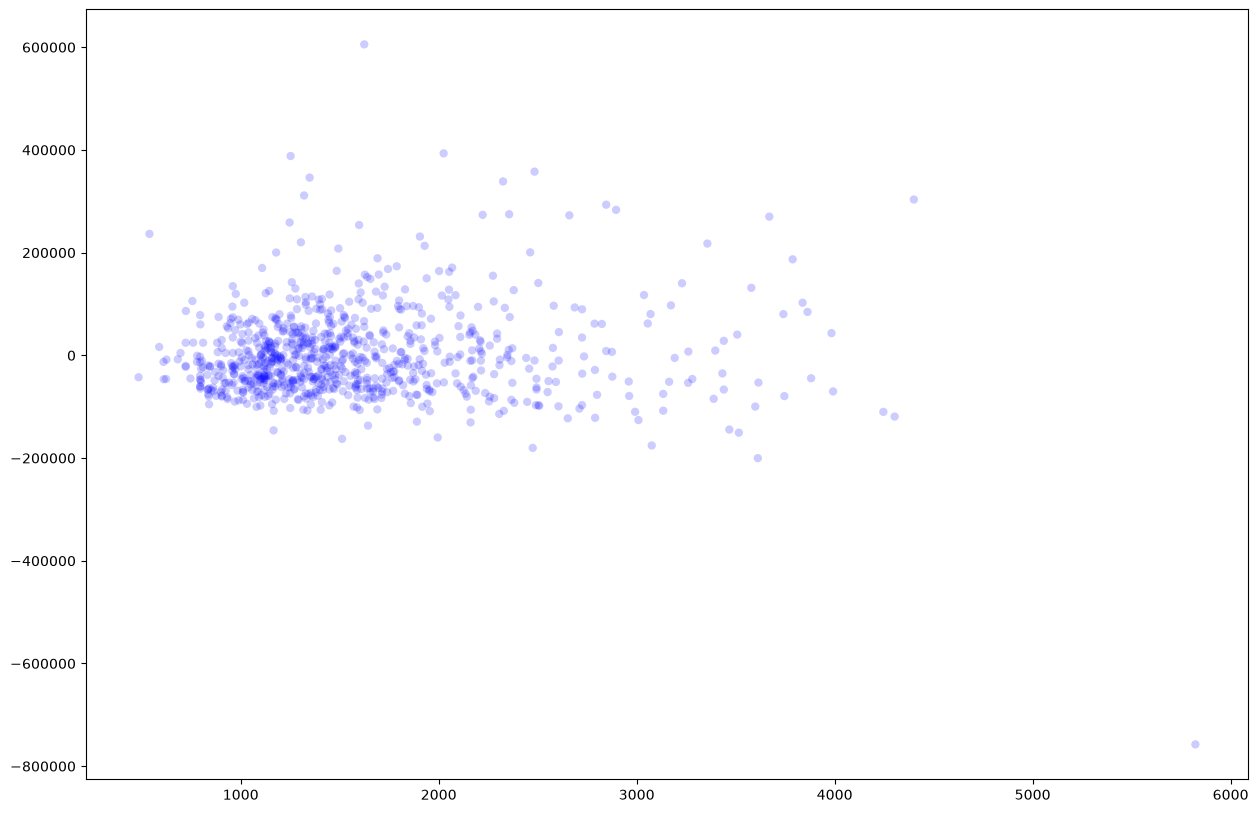

In [43]:
slope, intercept = linear_reg(X, y)

y_predict = intercept + slope*np.array(X).ravel()

res = y - y_predict

plt.figure(figsize=(15, 10))
plt.scatter(X, res, color='blue', alpha=0.2, edgecolors='none')

# I saw one outlier on the row 703 in the cleaned dataset.

---

## Reminder about categorical variables and dummy variables

It is important to be cautious with categorical variables, which represent distict groups or categories, when building a regression. If put in a regression "as-is," categorical variables represented as integers will be treated like *continuous* variables.

That is to say, instead of group "3" having a different effect on the estimation than group "1" it will estimate literally 3 times more than group 1. 

For example, if occupation category "1" represents "analyst" and occupation category "3" represents "barista", and our target variable is salary, if we leave this as a column of integers then barista will always have `beta*3` the effect of analyst.

This will almost certainly force the beta coefficient to be something strange and incorrect. Instead, we can re-represent the categories as multiple "dummy coded" columns.



#### A Word of Caution When Creating Dummies

Let's touch on precautions we should take when dummy coding.

**If you convert a qualitative variable to dummy variables, you want to turn a variable with N categories into N-1 variables.**

> **Scenario 1:** Suppose we're working with the variable "sex" or "gender" with values "M" and "F". 

You should include in your model only one variable for "sex = F" which takes on 1 if sex is female and 0 if sex is not female! Rather than saying "a one unit change in X," the coefficient associated with "sex = F" is interpreted as the average change in Y when sex = F relative to when sex = M.

| Female | Male | 
|-------|------|
| 0 | 1 | 
| 1 | 0 |
| 0 | 1 |
| 1 | 0 |
| 1 | 0 |
_As we can see a 1 in the female column indicates a 0 in the male column. And so, we have two columns stating the same information in different ways._

> Scenario 2: Suppose we're modeling revenue at a bar for each of the days of the week. We have a column with strings identifying which day of the week this observation occured in.

We might include six of the days as their own variables: "Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday". **But not all 7 days.**  

|Monday | Tuesday | Wednesday | Thursday | Friday | Saturday | 
|-------|---------|-----------|----------|--------|----------|
| 1     | 0       |0          |      0   |0       | 0        | 
| 0     | 1       |0          |      0   |0       | 0        | 
| 0     | 0       |1          |      0   |0       | 0        | 
| 0     | 0       |0          |      1   |0       | 0        | 
| 0     | 0       |0          |      0   |1       | 0        | 
| 0     | 0       |0          |      0   |0       | 1        | 
| 0     | 0       |0          |      0   |0       | 0        | 

_As humans we can infer from the last row that if its is not Monday, Tuesday, Wednesday, Thursday, Friday or Saturday, it must be Sunday. Models work the same way._

The coefficient for Monday is then interpreted as the average change in revenue when "day = Monday" relative to "day = Sunday." The coefficient for Tuesday is interpreted as the average change in revenue when "day = Tuesday" relative to "day = Sunday" and so on.

The category you leave out, which the other columns are *relative to*, is often referred to as the **reference category**.

### 9. Use the `pd.get_dummies` function to convert the `type` column into dummy-coded variables.

In [44]:
dfN.info()

<class 'pandas.DataFrame'>
Index: 812 entries, 0 to 812
Data columns (total 12 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   street     812 non-null    str    
 1   city       812 non-null    str    
 2   zip        812 non-null    int64  
 3   state      812 non-null    str    
 4   beds       812 non-null    int64  
 5   baths      812 non-null    int64  
 6   sq__ft     812 non-null    int64  
 7   type       812 non-null    str    
 8   sale_date  812 non-null    str    
 9   price      812 non-null    int64  
 10  latitude   812 non-null    float64
 11  longitude  812 non-null    float64
dtypes: float64(2), int64(5), str(5)
memory usage: 136.1 KB


In [45]:
dfN.columns

Index(['street', 'city', 'zip', 'state', 'beds', 'baths', 'sq__ft', 'type',
       'sale_date', 'price', 'latitude', 'longitude'],
      dtype='str')

In [46]:
dfd = pd.get_dummies(df, columns=['type'], drop_first=True, dtype=int)
dfd

,street,city,zip,state,beds,baths,sq__ft,sale_date,price,latitude,longitude,type_Multi-Family,type_Residential
0,3526 HIGH ST,SACRAMENTO,95838,CA,2,1,836,Wed May 21 00:00:00 EDT 2008,59222,38.631913,-121.434879,0,1
1,51 OMAHA CT,SACRAMENTO,95823,CA,3,1,1167,Wed May 21 00:00:00 EDT 2008,68212,38.478902,-121.431028,0,1
2,2796 BRANCH ST,SACRAMENTO,95815,CA,2,1,796,Wed May 21 00:00:00 EDT 2008,68880,38.618305,-121.443839,0,1
3,2805 JANETTE WAY,SACRAMENTO,95815,CA,2,1,852,Wed May 21 00:00:00 EDT 2008,69307,38.616835,-121.439146,0,1
4,6001 MCMAHON DR,SACRAMENTO,95824,CA,2,1,797,Wed May 21 00:00:00 EDT 2008,81900,38.519470,-121.435768,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
808,9169 GARLINGTON CT,SACRAMENTO,95829,CA,4,3,2280,Thu May 15 00:00:00 EDT 2008,232425,38.457679,-121.359620,0,1
809,6932 RUSKUT WAY,SACRAMENTO,95823,CA,3,2,1477,Thu May 15 00:00:00 EDT 2008,234000,38.499893,-121.458890,0,1
810,7933 DAFFODIL WAY,CITRUS HEIGHTS,95610,CA,3,2,1216,Thu May 15 00:00:00 EDT 2008,235000,38.708824,-121.256803,0,1
811,8304 RED FOX WAY,ELK GROVE,95758,CA,4,2,1685,Thu May 15 00:00:00 EDT 2008,235301,38.417000,-121.397424,0,1


In [47]:
dfd.describe(include=str)

,street,city,state,sale_date
count,813,813,813,813
unique,810,36,1,5
top,4734 14TH AVE,SACRAMENTO,CA,Fri May 16 00:00:00 EDT 2008
freq,2,423,813,215


In [48]:
dfd = pd.get_dummies(dfd, columns=['sale_date', 'city'], dtype=int)

In [49]:
dfd.columns

Index(['street', 'zip', 'state', 'beds', 'baths', 'sq__ft', 'price',
       'latitude', 'longitude', 'type_Multi-Family', 'type_Residential',
       'sale_date_Fri May 16 00:00:00 EDT 2008',
       'sale_date_Mon May 19 00:00:00 EDT 2008',
       'sale_date_Thu May 15 00:00:00 EDT 2008',
       'sale_date_Tue May 20 00:00:00 EDT 2008',
       'sale_date_Wed May 21 00:00:00 EDT 2008', 'city_ANTELOPE',
       'city_AUBURN', 'city_CAMERON PARK', 'city_CARMICHAEL',
       'city_CITRUS HEIGHTS', 'city_COOL', 'city_DIAMOND SPRINGS',
       'city_EL DORADO', 'city_EL DORADO HILLS', 'city_ELK GROVE',
       'city_ELVERTA', 'city_FAIR OAKS', 'city_FOLSOM', 'city_GALT',
       'city_GOLD RIVER', 'city_GRANITE BAY', 'city_GREENWOOD', 'city_LINCOLN',
       'city_LOOMIS', 'city_MATHER', 'city_MEADOW VISTA',
       'city_NORTH HIGHLANDS', 'city_ORANGEVALE', 'city_PENRYN',
       'city_PLACERVILLE', 'city_POLLOCK PINES', 'city_RANCHO CORDOVA',
       'city_RANCHO MURIETA', 'city_RIO LINDA', 'city_RO

### 10. Check the dummy columns you've created. Do they all make sense?

Use `.head()` on the new dataframe you've created. Depending on how you cleaned the data earlier in this notebook, there may be a dummy column that needs to be removed. Check that all the columns you've created make sense, and if any of the columns seem to be errors, drop them. If there don't appear to be any errors, then move on to the next step!

In [50]:
dfd.head()

,street,zip,state,beds,baths,sq__ft,price,latitude,longitude,type_Multi-Family,...,city_RANCHO CORDOVA,city_RANCHO MURIETA,city_RIO LINDA,city_ROCKLIN,city_ROSEVILLE,city_SACRAMENTO,city_SLOUGHHOUSE,city_WALNUT GROVE,city_WEST SACRAMENTO,city_WILTON
0,3526 HIGH ST,95838,CA,2,1,836,59222,38.631913,-121.434879,0,...,0,0,0,0,0,1,0,0,0,0
1,51 OMAHA CT,95823,CA,3,1,1167,68212,38.478902,-121.431028,0,...,0,0,0,0,0,1,0,0,0,0
2,2796 BRANCH ST,95815,CA,2,1,796,68880,38.618305,-121.443839,0,...,0,0,0,0,0,1,0,0,0,0
3,2805 JANETTE WAY,95815,CA,2,1,852,69307,38.616835,-121.439146,0,...,0,0,0,0,0,1,0,0,0,0
4,6001 MCMAHON DR,95824,CA,2,1,797,81900,38.519470,-121.435768,0,...,0,0,0,0,0,1,0,0,0,0


In [51]:
# everything is fine

# Multivariate Linear Regression Model (MLR)

### 11. Build what you think may be the best MLR model predicting `price`. 

Choose at least three variables, and build a model that uses them to predict price. At least one of the variables you choose should be a dummy-coded variable. (This can be one we created before or a new one.) 

You may need to load in the scikit-learn API:

```python
from sklearn.linear_model import LinearRegression

model = LinearRegression()
```

In [52]:
dfd.columns

Index(['street', 'zip', 'state', 'beds', 'baths', 'sq__ft', 'price',
       'latitude', 'longitude', 'type_Multi-Family', 'type_Residential',
       'sale_date_Fri May 16 00:00:00 EDT 2008',
       'sale_date_Mon May 19 00:00:00 EDT 2008',
       'sale_date_Thu May 15 00:00:00 EDT 2008',
       'sale_date_Tue May 20 00:00:00 EDT 2008',
       'sale_date_Wed May 21 00:00:00 EDT 2008', 'city_ANTELOPE',
       'city_AUBURN', 'city_CAMERON PARK', 'city_CARMICHAEL',
       'city_CITRUS HEIGHTS', 'city_COOL', 'city_DIAMOND SPRINGS',
       'city_EL DORADO', 'city_EL DORADO HILLS', 'city_ELK GROVE',
       'city_ELVERTA', 'city_FAIR OAKS', 'city_FOLSOM', 'city_GALT',
       'city_GOLD RIVER', 'city_GRANITE BAY', 'city_GREENWOOD', 'city_LINCOLN',
       'city_LOOMIS', 'city_MATHER', 'city_MEADOW VISTA',
       'city_NORTH HIGHLANDS', 'city_ORANGEVALE', 'city_PENRYN',
       'city_PLACERVILLE', 'city_POLLOCK PINES', 'city_RANCHO CORDOVA',
       'city_RANCHO MURIETA', 'city_RIO LINDA', 'city_RO

In [53]:
Xm = dfd[['beds', 'baths', 'sq__ft',
       'latitude', 'longitude', 'type_Multi-Family', 'type_Residential',
       'city_ANTELOPE',
       'city_AUBURN', 'city_CAMERON PARK', 'city_CARMICHAEL',
       'city_CITRUS HEIGHTS', 'city_COOL', 'city_DIAMOND SPRINGS',
       'city_EL DORADO', 'city_EL DORADO HILLS', 'city_ELK GROVE',
       'city_ELVERTA', 'city_FAIR OAKS', 'city_FOLSOM', 'city_GALT',
       'city_GOLD RIVER', 'city_GRANITE BAY', 'city_GREENWOOD', 'city_LINCOLN',
       'city_LOOMIS', 'city_MATHER', 'city_MEADOW VISTA',
       'city_NORTH HIGHLANDS', 'city_ORANGEVALE', 'city_PENRYN',
       'city_PLACERVILLE', 'city_POLLOCK PINES', 'city_RANCHO CORDOVA',
       'city_RANCHO MURIETA', 'city_RIO LINDA', 'city_ROCKLIN',
       'city_ROSEVILLE', 'city_SACRAMENTO', 'city_SLOUGHHOUSE',
       'city_WALNUT GROVE', 'city_WEST SACRAMENTO', 'city_WILTON'
       # 'sale_date_Fri May 16 00:00:00 EDT 2008',
       # 'sale_date_Mon May 19 00:00:00 EDT 2008',
       # 'sale_date_Thu May 15 00:00:00 EDT 2008',
       # 'sale_date_Tue May 20 00:00:00 EDT 2008',
       # 'sale_date_Wed May 21 00:00:00 EDT 2008'
       ]]
ym = dfd['price']

In [54]:
model.fit(Xm, ym)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](43,)","[-20596.25, 4393.97, 133.66,...,101962.58,-57939.31,139826.17]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](43,)","['beds','baths','sq__ft',...,'city_WALNUT GROVE','city_WEST SACRAMENTO', 'city_WILTON']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-7.673e+06
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,43
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(42)


In [55]:
y_predm = model.predict(Xm)

In [56]:
from sklearn.metrics import root_mean_squared_error, mean_squared_error

RMSEM = root_mean_squared_error(y_predm, ym)
MSEM = mean_squared_error(y_predm, ym)
SSEM = ((y_predm -ym)**2).sum()

print("RMSE = %.2f \nMSE = %.2f \nSSE = %.2f" %(RMSEM, MSEM, SSEM))

RMSE = 67970.80 
MSE = 4620029167.71 
SSE = 3756083713348.96


### 12. Plot the true price vs the predicted price to evaluate your MLR visually.

You can use matplotlib or seaborn, the choice is yours ! 

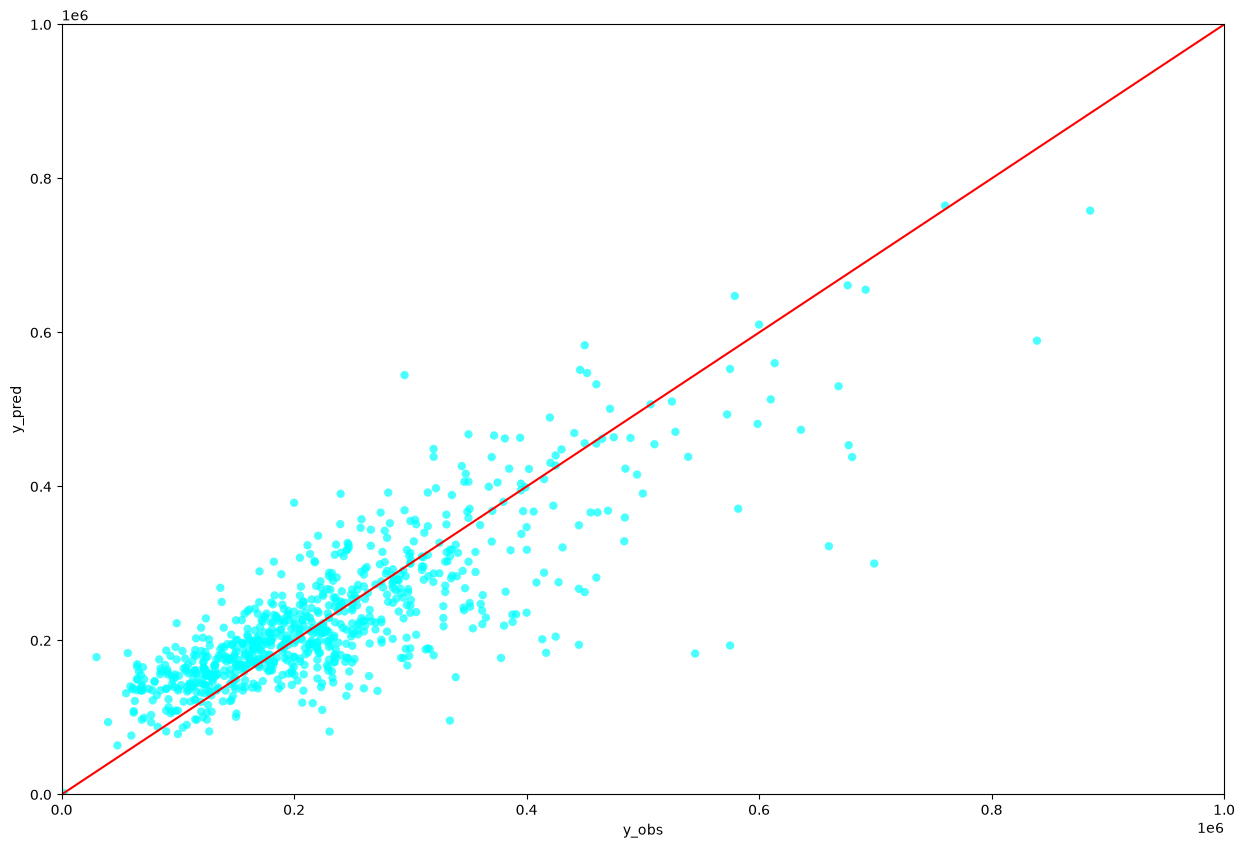

In [57]:
plt.figure(figsize=(15, 10))
plt.scatter(ym, y_predm, color='cyan', alpha=0.7, edgecolors='none')
plt.xlabel("y_obs")
plt.ylabel("y_pred")
plt.xlim(0,1000000)
plt.ylim(0,1000000)
plt.plot(np.arange(0, 1000000), np.arange(0,1000000), c='r')

In [58]:
model.coef_

array([-2.05962518e+04,  4.39396866e+03,  1.33664615e+02,  5.72313373e+04,
       -4.56097758e+04,  4.37219468e+03,  4.58811667e+04, -6.03193324e+04,
        7.14397950e+04,  7.72666696e+04,  3.12398457e+04, -4.66750872e+04,
        4.06119561e+04, -2.38943690e+03,  1.45544036e+04,  1.87796707e+04,
       -3.69673718e+04, -1.01706353e+05,  2.32425406e+04,  7.45121736e+04,
       -2.12445883e+04,  2.43821031e+04,  2.45739357e+05, -4.92787544e+04,
       -2.64158186e+04,  3.17538427e+05, -1.00038886e+05, -1.41675555e+03,
       -8.53610406e+04,  3.03664631e+03,  2.59559973e+05,  1.30888737e+05,
        1.89246448e+04, -5.43368177e+04, -2.61411828e+04, -5.21048704e+04,
        2.20906277e+04, -2.98135648e+03, -5.74042353e+04, -8.32875119e+05,
        1.01962582e+05, -5.79393136e+04,  1.39826166e+05])

### 13. List the five assumptions for an MLR model. 

Indicate which ones are the same as the assumptions for an SLR model. 

#### convert this cell to markdown to provide your answer

price will linearly rise with increasing of the columns with positive coeff and fall for the negative coeff colummns ...


### 14. Pick at least two assumptions and explain whether or not you believe them to be met for your model, and explain why.

### 15. [Bonus - optional] Generate a table showing the point estimates, standard errors, t-scores, p-values, and 95% confidence intervals for the model you built. 

**Write a few sentences interpreting some of the output.**

> **Hint:** scikit-learn does not have this functionality built in, but statsmodels does in the `summary` method.  To fit the statsmodels model use something like the following.  There is one big caveat here, however!  `statsmodels.OLS` does _not_ add an intercept to your model, so you will need to do this explicitly by adding a column filled with the number 1 to your X matrix

```python
import statsmodels.api as sm

# The Default here is Linear Regression (ordinary least squares regression OLS)
model = sm.OLS(y,X).fit()
```

### 16. Metrics, metrics, everywhere...

Calculate and interpret at least three regression metrics. How well does your model perform?

## Metric Comparison Table

| Metric | What It Tells You | Punishes Big Mistakes? | Adjusts for Extra Inputs? | Examples of When to Use It |
|---|---|---|---|---|
| **R²** | What percent of the output's variation did the model explain? (0% to 100%) | Indirectly | ❌ No | • Pitching model quality in a presentation: "My model explains 73% of the price variation."<br>• Comparing two models on the same dataset.<br>• Quick sanity check: if R² is near zero, your inputs aren't helping. |
| **Adjusted R²** | Like R², but penalizes you for throwing in too many inputs | Indirectly | ✅ Yes | • You add/remove variables and want to know if performance truly improved.<br>• Deciding whether a new feature is worth keeping in production.<br>• Anytime you're comparing models with different numbers of predictors. |
| **MSE** | Average squared error. Lower is better. | ✅ Strongly (squared!) | ❌ No | • The loss function that regression algorithms optimize internally.<br>• Math-heavy contexts (calculus, derivation).<br>• Rarely reported to stakeholders — too abstract. |
| **RMSE** | On average, how far off are predictions (in original units)? | ✅ Strongly | ❌ No | • "Predictions are off by ~$45,000 on average."<br>• Reporting to non-technical audiences who want dollar amounts.<br>• When large outliers matter and you want to catch them. |
| **MAE** | On average, how far off are predictions (in original units)? | ❌ Mildly (linear) | ❌ No | • When outliers are noisy measurements you don't want to overweight.<br>• Plain-language explanations: "Typical error is about $40,000."<br>• When you want a robust, easy-to-grasp error measure. |

---

## Which Metrics to Report?

**Quick analogy:** If you're reporting to your professor, think of it like grading on multiple axes:
- **R²** answers: "How much of the puzzle did you solve?"
- **RMSE/MAE** answer: "By how many points, on average, were your answers wrong?"
- **Adjusted R²** answers: "Did you actually improve, or just throw more pages at the problem?"

### 16. [Bonus - Optional] Regression Metrics

Implement a function called `r2_adj()` that will calculate $R^2_{adj}$ for a model. 

### 18. Model Iteration

Adjust your model by adding or removing a variable. Then calculate the same regression metrics as you used in question 17. Has your model performance increased or decreased?

### 19. Bias vs. Variance

At this point, do you think your model is high bias, high variance or in the
sweet spot?

Hint: cross validation, test ... !